# 29 - Can a tiny-model ladder predict the 30M outcome? (Phase 1: retrospective test)

**The question behind paper #2:** everyone selects architecture changes with small cheap ablations,
then scales up. Our own data shows effects can *flip sign* with scale (conv: +20% harm at 5M ->
-10% gain at 29M). So: **how well does the obvious procedure — fit effect-vs-logN on tiny rungs,
extrapolate — actually predict the larger-scale outcome?** We already own the expensive truth
(29.4M, 2 seeds), so Phase 1 is free: pretend we never saw 29.4M, predict it from the small rungs,
then uncover.

**Data inventory (all WikiText-103 BPE, block 256):**

| source | size | token budget | protocol |
|---|---|---|---|
| crossover_runs | 5.25M, 10.0M | 12.3M tok | 3000 it, batch 16, seeds 0,1 |
| conv_disambig_runs | 5.25M | 24.6M tok | 3000 it, batch 32, seeds 0,1 |
| scale_confirm(+s1) | 29.4M | 24.6M tok | 6000 it, batch 16, seeds 0,1 |
| scalesafe / scalesafe30 | 5.25M / 29.4M | 12.3M / 24.6M tok | gated-conv control |

**Honesty caveat, stated up front:** the tiny rungs (12.3M tok) and the 29.4M anchor (24.6M tok)
differ in token budget, so part of any prediction error may be budget, not model size. Notebook 30
re-runs the ladder at the matched 24.6M-token budget to remove this. Phase 1 is the preliminary,
clearly-flagged version — and includes a near-matched-budget slope check (batch-32 rung) that the
curvature survives.


In [1]:
import csv, math
import numpy as np

R = "../results"

def load_rows(fn, cols):
    rows = []
    with open(f"{R}/{fn}") as f:
        r = csv.reader(f); next(r, None)
        for row in r:
            if len(row) == len(cols):
                rows.append(dict(zip(cols, row)))
    return rows

# ---- tiny rungs, 12.3M-token budget (3000 it, batch 16) ----
cross = load_rows("crossover_runs.csv", ["size", "variant", "seed", "params_M", "val_ppl"])
# ---- 29.4M anchor, 24.6M-token budget (6000 it, batch 16), per-seed files ----
s0 = {r["config"]: float(r["val_ppl"]) for r in load_rows("scale_confirm_runs.csv", ["config", "params_M", "val_ppl"])}
s1 = {r["config"]: float(r["val_ppl"]) for r in load_rows("scale_confirm_s1_runs.csv", ["config", "params_M", "val_ppl"])}
# ---- 5.25M near-matched budget (24.6M tok, but batch 32) ----
dis = load_rows("conv_disambig_runs.csv", ["config", "seed", "params_M", "val_ppl"])
# ---- gated-conv control ----
gate3 = load_rows("scalesafe_runs.csv", ["config", "seed", "params_M", "val_ppl"])
gate30 = load_rows("scalesafe30_runs.csv", ["seed", "params_M", "val_ppl"])

def ppl(rows, size, variant, seed):
    for r in rows:
        if r.get("size", None) == size and r["variant"] == variant and r["seed"] == str(seed):
            return float(r["val_ppl"])
    raise KeyError((size, variant, seed))

# seed-paired relative effect Delta% = 100*(ppl_variant - ppl_combo)/ppl_combo
def delta_pair(get_v, get_c, seeds=(0, 1)):
    ds = [100.0 * (get_v(s) - get_c(s)) / get_c(s) for s in seeds]
    return float(np.mean(ds)), float(np.std(ds)), ds

P = {"3M": 5.254, "10M": 10.016, "30M": 29.407}   # combo params_M per rung; "3M" is the CSV's
                                                  # legacy label for the 5.25M-param BPE model
X = {k: math.log10(v * 1e6) for k, v in P.items()}

print("=== per-size effects, seed-paired (Delta% vs combo; negative = intervention wins) ===")
eff = {}
for variant in ["combo_conv3", "combo_diff"]:
    for size in ["3M", "10M"]:
        m, sd, _ = delta_pair(lambda s: ppl(cross, size, variant, s), lambda s: ppl(cross, size, "combo", s))
        eff[(variant, size)] = (m, sd)
        print(f"  {variant:12s} @ {P[size]:6.2f}M (12.3M tok): {m:+6.2f}%  (seed spread +/-{sd:.2f})")
truth = {}
for variant in ["combo_conv3", "combo_diff"]:
    m, sd, _ = delta_pair(lambda s: (s0 if s == 0 else s1)[variant], lambda s: (s0 if s == 0 else s1)["combo"])
    truth[variant] = (m, sd)
    print(f"  {variant:12s} @  29.41M (24.6M tok): {m:+6.2f}%  (seed spread +/-{sd:.2f})   <- held-out truth")
# near-matched-budget 5.25M point (24.6M tok, batch 32)
near = {}
for variant in ["combo_conv3", "combo_diff"]:
    vv = {r["seed"]: float(r["val_ppl"]) for r in dis if r["config"] == variant}
    cc = {r["seed"]: float(r["val_ppl"]) for r in dis if r["config"] == "combo"}
    ds = [100.0 * (vv[s] - cc[s]) / cc[s] for s in ("0", "1")]
    near[variant] = (float(np.mean(ds)), float(np.std(ds)))
    print(f"  {variant:12s} @   5.25M (24.6M tok, batch32): {near[variant][0]:+6.2f}%  (+/-{near[variant][1]:.2f})")
print("ready")


=== per-size effects, seed-paired (Delta% vs combo; negative = intervention wins) ===
  combo_conv3  @   5.25M (12.3M tok): +20.15%  (seed spread +/-1.59)
  combo_conv3  @  10.02M (12.3M tok): +12.78%  (seed spread +/-0.35)
  combo_diff   @   5.25M (12.3M tok): +31.55%  (seed spread +/-0.60)
  combo_diff   @  10.02M (12.3M tok): +28.81%  (seed spread +/-0.06)
  combo_conv3  @  29.41M (24.6M tok): -10.23%  (seed spread +/-0.41)   <- held-out truth
  combo_diff   @  29.41M (24.6M tok):  +3.95%  (seed spread +/-2.24)   <- held-out truth
  combo_conv3  @   5.25M (24.6M tok, batch32): +19.48%  (+/-1.63)
  combo_diff   @   5.25M (24.6M tok, batch32): +23.99%  (+/-0.69)
ready


In [2]:
# === TEST A: the standard procedure - linear fit in log10(N) on the tiny rungs only ===
# per-seed points (2 sizes x 2 seeds = 4 points per intervention), extrapolate to 29.4M, then uncover.
results = {}
print("=== Test A: fit on {5.25M, 10M} only -> predict 29.4M ===")
for variant, label in [("combo_conv3", "depthwise conv"), ("combo_diff", "differential attn")]:
    xs, ys = [], []
    for size in ["3M", "10M"]:
        for s in (0, 1):
            c = ppl(cross, size, "combo", s); v = ppl(cross, size, variant, s)
            xs.append(X[size]); ys.append(100.0 * (v - c) / c)
    slope, intercept = np.polyfit(xs, ys, 1)
    pred30 = slope * X["30M"] + intercept
    act30, act30sd = truth[variant]
    nstar_pred = 10 ** (-intercept / slope) / 1e6 if slope != 0 else float("inf")
    results[variant] = dict(slope=slope, intercept=intercept, pred30=pred30,
                            act30=act30, act30sd=act30sd, nstar_pred=nstar_pred)
    print(f"\n  {label} ({variant})")
    print(f"    fitted slope          : {slope:+.2f} % per decade of params")
    print(f"    PREDICTED at 29.4M    : {pred30:+.2f}%")
    print(f"    ACTUAL at 29.4M       : {act30:+.2f}%  (+/-{act30sd:.2f})")
    print(f"    prediction error      : {pred30 - act30:+.2f} percentage points")
    sign_pred = "helps" if pred30 < 0 else "hurts/neutral"
    sign_act = "helps" if act30 < 0 else "hurts/neutral"
    print(f"    sign call             : predicted '{sign_pred}', actually '{sign_act}'"
          + ("   <<< SIGN WRONG" if (pred30 < 0) != (act30 < 0) else "   (sign ok)"))
    print(f"    implied crossover N*  : {nstar_pred:,.0f}M params")

with open(f"{R}/extrapolation_prelim.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["variant", "slope_pct_per_decade", "pred_at_29.4M_pct", "actual_at_29.4M_pct",
                "error_pp", "implied_crossover_M"])
    for v, d in results.items():
        w.writerow([v, f"{d['slope']:.3f}", f"{d['pred30']:.3f}", f"{d['act30']:.3f}",
                    f"{d['pred30']-d['act30']:.3f}", f"{d['nstar_pred']:.1f}"])
print(f"\nsaved {R}/extrapolation_prelim.csv")


=== Test A: fit on {5.25M, 10M} only -> predict 29.4M ===

  depthwise conv (combo_conv3)
    fitted slope          : -26.31 % per decade of params
    PREDICTED at 29.4M    : +0.47%
    ACTUAL at 29.4M       : -10.23%  (+/-0.41)
    prediction error      : +10.70 percentage points
    sign call             : predicted 'hurts/neutral', actually 'helps'   <<< SIGN WRONG
    implied crossover N*  : 31M params

  differential attn (combo_diff)
    fitted slope          : -9.77 % per decade of params
    PREDICTED at 29.4M    : +24.24%
    ACTUAL at 29.4M       : +3.95%  (+/-2.24)
    prediction error      : +20.29 percentage points
    sign call             : predicted 'hurts/neutral', actually 'hurts/neutral'   (sign ok)
    implied crossover N*  : 8,925M params

saved ../results/extrapolation_prelim.csv


In [3]:
# === TEST B: is the miss just the token-budget confound? Slope-steepening check ===
# Short-range slope (5.25 -> 10M, matched 12.3M-tok budget)  vs
# long-range slope  (5.25 -> 29.4M, both at 24.6M tok; 5.25M rung is batch32 - caveat)
print("=== Test B: short-range vs long-range slope (% per decade of N) ===")
for variant, label in [("combo_conv3", "depthwise conv"), ("combo_diff", "differential attn")]:
    short = results[variant]["slope"]
    d_near, _ = near[variant]          # 5.25M @ 24.6M tok (batch32)
    d_far, _ = truth[variant]          # 29.4M @ 24.6M tok
    long_slope = (d_far - d_near) / (X["30M"] - X["3M"])
    print(f"  {label:18s}: short-range {short:+7.2f}   long-range {long_slope:+7.2f}"
          f"   -> steepens by x{long_slope/short:.1f}" if short != 0 else "")
print()
print("Both interventions steepen substantially between the tiny rungs and the wide interval,")
print("*including when both endpoints share the 24.6M-token budget* (batch caveat noted).")
print("=> Delta(logN) is CONVEX here: a linear fit on tiny rungs is systematically CONSERVATIVE -")
print("   it underestimates how quickly an intervention's relative value improves with scale.")
print()
nstar_diff = results["combo_diff"]["nstar_pred"]
print(f"Dramatic version: the tiny ladder says differential attention breaks even at ~{nstar_diff:,.0f}M")
print(f"params (~{nstar_diff/1000:.1f}B). The near-matched-budget trend (still +{near['combo_diff'][0]:.1f}% at 5.25M but")
print(f"only {truth['combo_diff'][0]:+.1f}% at 29.4M) points to a crossover only a small factor above 30M.")


=== Test B: short-range vs long-range slope (% per decade of N) ===
  depthwise conv    : short-range  -26.31   long-range  -39.72   -> steepens by x1.5
  differential attn : short-range   -9.77   long-range  -26.79   -> steepens by x2.7

Both interventions steepen substantially between the tiny rungs and the wide interval,
*including when both endpoints share the 24.6M-token budget* (batch caveat noted).
=> Delta(logN) is CONVEX here: a linear fit on tiny rungs is systematically CONSERVATIVE -
   it underestimates how quickly an intervention's relative value improves with scale.

Dramatic version: the tiny ladder says differential attention breaks even at ~8,925M
params (~8.9B). The near-matched-budget trend (still +24.0% at 5.25M but
only +4.0% at 29.4M) points to a crossover only a small factor above 30M.


In [4]:
# === Control: the gated conv (flat trajectory) - does the naive method work when Delta is flat? ===
g3v = {r["seed"]: float(r["val_ppl"]) for r in gate3 if r["config"] == "combo_conv3_gated"}
g3c = {r["seed"]: float(r["val_ppl"]) for r in gate3 if r["config"] == "combo"}
d3 = [100.0 * (g3v[s] - g3c[s]) / g3c[s] for s in ("0", "1")]
g30v = {r["seed"]: float(r["val_ppl"]) for r in gate30}
d30 = [100.0 * (g30v[s] - (s0 if s == "0" else s1)["combo"]) / (s0 if s == "0" else s1)["combo"] for s in ("0", "1")]
print("=== Control: zero-init GATED conv (a flat, weak intervention) ===")
print(f"  @ 5.25M: {np.mean(d3):+.2f}%   @ 29.4M: {np.mean(d30):+.2f}%")
print("  A tiny-rung fit would predict 'about zero at 30M' -> and that is what happens.")
print("  => the naive procedure is fine for FLAT interventions; it fails for strongly")
print("     scale-dependent ones - exactly the cases where the answer matters most.")


=== Control: zero-init GATED conv (a flat, weak intervention) ===
  @ 5.25M: -0.70%   @ 29.4M: -1.12%
  A tiny-rung fit would predict 'about zero at 30M' -> and that is what happens.
  => the naive procedure is fine for FLAT interventions; it fails for strongly
     scale-dependent ones - exactly the cases where the answer matters most.


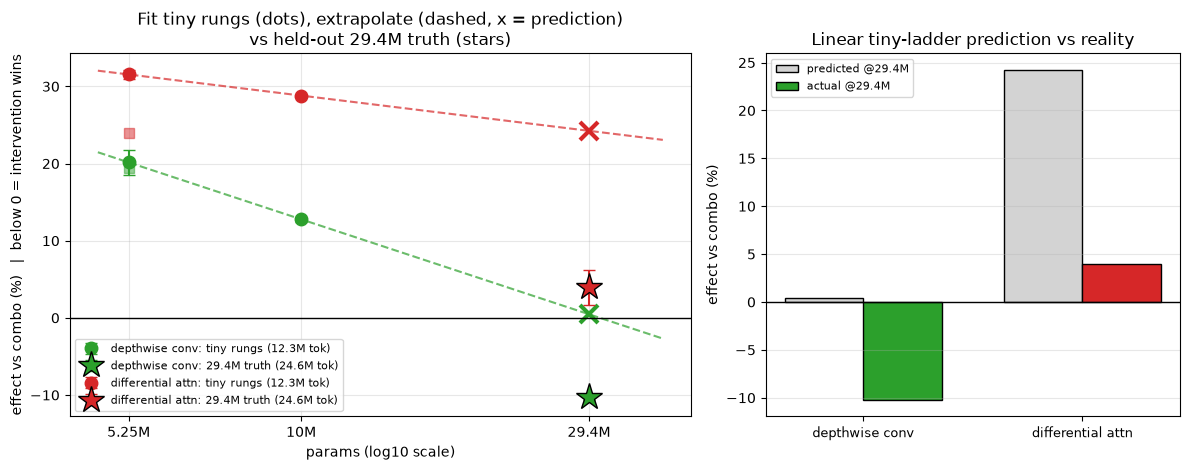

saved ../results/fig_extrapolation_prelim.png


In [5]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

colors = {"combo_conv3": "tab:green", "combo_diff": "tab:red"}
labels = {"combo_conv3": "depthwise conv", "combo_diff": "differential attn"}
xgrid = np.linspace(X["3M"] - 0.05, X["30M"] + 0.12, 100)
for variant in ["combo_conv3", "combo_diff"]:
    c = colors[variant]
    xs = [X["3M"], X["10M"]]
    ys = [eff[(variant, "3M")][0], eff[(variant, "10M")][0]]
    es = [eff[(variant, "3M")][1], eff[(variant, "10M")][1]]
    ax1.errorbar(xs, ys, yerr=es, fmt="o", color=c, ms=9, capsize=4,
                 label=f"{labels[variant]}: tiny rungs (12.3M tok)")
    d = results[variant]
    ax1.plot(xgrid, d["slope"] * xgrid + d["intercept"], "--", color=c, alpha=0.7)
    ax1.plot(X["30M"], d["pred30"], "x", color=c, ms=13, mew=3)
    ax1.errorbar([X["30M"]], [d["act30"]], yerr=[d["act30sd"]], fmt="*", color=c, ms=20,
                 capsize=4, markeredgecolor="k", label=f"{labels[variant]}: 29.4M truth (24.6M tok)")
    ax1.plot(X["3M"], near[variant][0], "s", color=c, ms=7, alpha=0.5)
ax1.axhline(0, color="k", lw=1)
ax1.set_xticks([X["3M"], X["10M"], X["30M"]])
ax1.set_xticklabels(["5.25M", "10M", "29.4M"])
ax1.set_xlabel("params (log10 scale)")
ax1.set_ylabel("effect vs combo (%)   |  below 0 = intervention wins")
ax1.set_title("Fit tiny rungs (dots), extrapolate (dashed, x = prediction)\nvs held-out 29.4M truth (stars)")
ax1.legend(fontsize=8, loc="lower left")
ax1.grid(alpha=0.3)

names = [labels[v] for v in results]
preds = [results[v]["pred30"] for v in results]
acts = [results[v]["act30"] for v in results]
xpos = np.arange(len(names))
ax2.bar(xpos - 0.18, preds, 0.36, color="lightgray", edgecolor="k", label="predicted @29.4M")
ax2.bar(xpos + 0.18, acts, 0.36, color=[colors[v] for v in results], edgecolor="k", label="actual @29.4M")
ax2.axhline(0, color="k", lw=1)
ax2.set_xticks(xpos); ax2.set_xticklabels(names, fontsize=9)
ax2.set_ylabel("effect vs combo (%)")
ax2.set_title("Linear tiny-ladder prediction vs reality")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("../results/fig_extrapolation_prelim.png", dpi=150)
plt.show()
print("saved ../results/fig_extrapolation_prelim.png")


## Reading this (preliminary - budget caveat applies)

1. **The standard procedure fails where it matters.** A linear-in-logN fit on cheap rungs
   (5.25M, 10M) predicts conv is still *neutral/harmful* at 29.4M (sign wrong: actual -10.2%)
   and predicts diff needs ~billions of params to break even (the near-matched trend says the
   crossover is only a small factor above 30M).
2. **The failure is systematic, not noise:** Delta(logN) is convex for both interventions -
   short-range slopes understate long-range slopes - so linear tiny-ladder extrapolation is
   *conservative by construction* on accelerating interventions.
3. **The flat control passes**, so the procedure's failure is specific to scale-dependent
   interventions - exactly the ones ablation studies are supposed to catch.

**What Phase 2 (notebook 30) adds:** the same ladder re-run at the *matched* 24.6M-token budget
(5.25M / 10M / 15.5M / 20.5M, 2 seeds, combo/conv/diff) so the prediction test is clean, plus
enough rungs to fit a curvature-aware form and *pre-register* a prediction for ~90M before running it.
